# SmartCrop — Master Data Science Pipeline

**Project:** SmartCrop Yield Prediction Model for Smallholder Farmers  
**Location:** Macheke, Mashonaland East, Zimbabwe  
**Crop:** Maize (*Zea mays*)  
**Target Variable:** `yield_t_ha` (Grain yield in tonnes per hectare)  
**Methodology:** Consolidates Chapter 3 research notebooks 01 through 07 in deterministic execution order.  
**Generated:** 2026-10-12 10:40:59 UTC  

> **Important Data Provenance & Ethics Notice:**  
> Rows in `data/synthetic/` and `data/interim/consolidated_raw.csv` were created for software and model-development exercises. > They are **not a survey of Macheke farms** and must not be cited as ZIMSTAT, Agritex, NASA POWER, CHIRPS, or SoilGrids measurements. > The academic performance target used here is **test $R^2 \ge 0.80$**, which is **not met** on the synthetic held-out seasons. > $R^2$ is the coefficient of determination for continuous yield, not classification accuracy. > Predictions generated by the saved model are estimates and not a guaranteed harvest.

### Pipeline Overview
1. **Part 1: Data Acquisition & Understanding** (`01_data_acquisition.ipynb`)
2. **Part 2: Data Cleaning & Preparation** (`02_data_cleaning.ipynb`)
3. **Part 3: Feature Engineering** (`03_feature_engineering.ipynb`)
4. **Part 4: Exploratory & Descriptive Analysis** (`04_eda_and_descriptive_analysis.ipynb`)
5. **Part 5: Model Training & Comparison** (`05_model_training.ipynb`)
6. **Part 6: Model Evaluation & Diagnostics** (`06_model_evaluation.ipynb`)
7. **Part 7: Final Model & Deployment** (`07_final_model.ipynb`)

---


---
# Part 1: Data Acquisition and Understanding

**Chapter 3 Stage:** Data Acquisition & Understanding  
**Original Source Notebook:** [`01_data_acquisition.ipynb`](01_data_acquisition.ipynb)  
**Execution Order:** Step 1 of 7  

Loads raw CSV/Excel observation batches and source catalogue, checks schema units and multisets, and creates the consolidated raw dataset.


# SmartCrop — Notebook 01: Data Acquisition

**Project:** Smart Crop Yield Prediction for smallholder maize in Macheke  
**Study area:** Macheke, Mashonaland East, Zimbabwe  
**Crop:** Maize only  
**Target:** `yield_t_ha` (tonnes per hectare)  

> **Data status.** The observation files loaded here are **synthetic**. They were produced by `generate_synthetic_dataset.py` so the pipeline can be built before a real Macheke extract is available. They are not farm measurements and they are not ZIMSTAT, Agritex, NASA POWER, CHIRPS, or SoilGrids data. The external file is a source catalogue. Its status is `not_ingested`. It contains no measurements.


## 1. Introduction

SmartCrop predicts maize yield in tonnes per hectare for the Macheke study area. Total production is not the target. If cultivated area is known, production can be derived later:

`production_tonnes = yield_t_ha × area_ha`

This notebook is the acquisition step:

`raw CSV + raw Excel → one consolidated raw table`

It records what was loaded, which units the columns use, and a first quality summary. It does not impute values, delete rows, or train a model. Cleaning starts in Notebook 02.


## 2. Objectives

1. Load the CSV batch and the Excel batch of synthetic farm-season observations.
2. Load the external source catalogue and confirm that it contains no measurements.
3. Inspect columns, data types, units, and row counts.
4. Count duplicate records and missing values.
5. Save `data/interim/consolidated_raw.csv`.
6. Save a quality summary under `reports/tables/` and one missing-value figure under `reports/figures/`.


## 3. Dataset Description

Each observation row is one synthetic farm in one synthetic season.

| Item | Definition used in this project |
| --- | --- |
| Crop | `maize` only |
| Location | `Macheke` |
| Province | `Mashonaland East` |
| Country | `Zimbabwe` |
| Target | `yield_t_ha`, tonnes of maize grain per hectare |
| Planting day | Day index with 1 = 1 November. A value of 45 is 15 December. |
| Fertilizer | Product applied, kg/ha, not an elemental nutrient rate |
| Soil nitrogen | Percent by mass |
| Soil organic carbon | Percent. A future SoilGrids value in g/kg would be divided by 10 |
| Ward | Placeholder codes `SYN-W01` to `SYN-W06`, not official ward names |
| Season | Labels such as `2016/2017`. The label is not historical weather for that year |
| `data_source_type` | `SYNTHETIC` on these rows. Allowed project values are `REAL`, `SYNTHETIC`, and `EXTERNAL` |

The generator also blanks some feature cells, inserts a few extreme values, and appends a few exact duplicate rows. Those defects are intentional so later cleaning work has something to find. Identity columns such as `record_id`, `crop`, and `data_source_type` are not blanked.


## 4. Methodology

1. Locate the `data-science` directory from the current working directory.
2. Read `data/raw/batch_a_farm_observations.csv`.
3. Read `data/raw/batch_b_farm_observations.xlsx`, sheet `observations`.
4. Read `data/external/source_catalogue.csv` and keep it **out** of the observation table. A catalogue row is a data source, not a farm-season.
5. Coerce both batches onto the shared column list and dtypes in `src/data/schema.py`.
6. Concatenate the batches. Check that together they contain the same `record_id` values as `data/synthetic/macheke_maize_synthetic.csv`.
7. Summarise missingness, exact duplicates, values outside the documented plausible ranges, and simple consistency checks.
8. Write the consolidated CSV and the quality tables.

The batch split exists so this notebook can demonstrate CSV and Excel ingestion. Both batches come from one seeded generator run. They are not two independent surveys.

No value is corrected in this notebook. A flag in the quality table is a description, not a deletion.


## 5. Implementation


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

def find_data_science_root() -> Path:
    # Works when the kernel starts in notebooks/ or in a parent of data-science/.
    start = Path.cwd().resolve()
    candidates = [start, *start.parents]
    if (start / "data-science").is_dir():
        candidates.insert(0, start / "data-science")
    for candidate in candidates:
        marker = candidate / "src" / "data" / "schema.py"
        if marker.is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find the data-science root. Run the notebook from the smartcrop repository."
    )

DS_ROOT = find_data_science_root()
SRC = DS_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data.quality import (
    consistency_summary,
    duplicate_summary,
    format_quality_report,
    missing_summary,
    range_summary,
    source_summary,
    structure_summary,
)
from data.schema import (
    OBSERVATION_COLUMNS,
    SYNTHETIC_DISCLAIMER,
    coerce_observation_frame,
    units_table,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "font.size": 10,
})

print(SYNTHETIC_DISCLAIMER)
print()
print(f"Data-science root: {DS_ROOT}")


SYNTHETIC DATA. These rows were generated by the SmartCrop synthetic generator for software and model-development exercises. They are not measurements from Macheke, Mashonaland East, Zimbabwe, and they must not be cited as agricultural statistics.

Data-science root: /home/marvelous/.dev/Tait/capstone/data-science


### 5.1 Load the CSV batch

`batch_a_farm_observations.csv` is the first half of the synthetic master file. Column names follow the project schema.


In [2]:
csv_path = DS_ROOT / "data" / "raw" / "batch_a_farm_observations.csv"
if not csv_path.is_file():
    raise FileNotFoundError(
        f"Missing {csv_path}. From data-science/, run: python generate_synthetic_dataset.py"
    )

batch_csv_raw = pd.read_csv(csv_path)
batch_csv = coerce_observation_frame(batch_csv_raw)

print(f"File: {csv_path.name}")
print(f"Rows: {len(batch_csv)}")
print(f"Columns: {batch_csv.shape[1]}")
print(f"data_source_type values: {sorted(batch_csv['data_source_type'].dropna().unique())}")
batch_csv.head()


File: batch_a_farm_observations.csv
Rows: 487
Columns: 23
data_source_type values: ['SYNTHETIC']


,record_id,farm_id,year,season,country,province,location,ward,crop,area_ha,rainfall_mm,avg_temperature_c,max_temperature_c,min_temperature_c,soil_ph,soil_nitrogen,soil_organic_carbon,fertilizer_kg_ha,planting_day,yield_t_ha,data_source_type,data_source,schema_version
0,SC-SYN-000200,F0080,2018,2017/2018,Zimbabwe,Mashonaland East,Macheke,SYN-W05,maize,0.80,651.3,24.82,31.95,17.53,5.31,0.094,0.72,99.3,40,2.267,SYNTHETIC,smartcrop_synthetic_generator_v1,1.0.0
1,SC-SYN-000540,F0060,2021,2020/2021,Zimbabwe,Mashonaland East,Macheke,SYN-W04,maize,1.00,768.5,24.43,34.74,17.44,6.15,0.129,1.31,0.0,27,1.782,SYNTHETIC,smartcrop_synthetic_generator_v1,1.0.0
2,SC-SYN-000175,F0055,2018,2017/2018,Zimbabwe,Mashonaland East,Macheke,SYN-W05,maize,1.45,679.5,24.29,31.36,18.41,5.54,0.094,0.85,172.8,46,2.032,SYNTHETIC,smartcrop_synthetic_generator_v1,1.0.0
3,SC-SYN-000466,F0106,2020,2019/2020,Zimbabwe,Mashonaland East,Macheke,SYN-W06,maize,1.11,902.8,22.52,29.82,15.94,6.21,0.143,1.46,206.7,22,2.089,SYNTHETIC,smartcrop_synthetic_generator_v1,1.0.0
4,SC-SYN-000067,F0067,2017,2016/2017,Zimbabwe,Mashonaland East,Macheke,SYN-W05,maize,0.56,NaN,22.83,29.51,16.70,5.54,0.097,0.87,323.4,36,1.890,SYNTHETIC,smartcrop_synthetic_generator_v1,1.0.0


### 5.2 Load the Excel batch

`batch_b_farm_observations.xlsx` is the second half of the same synthetic run. It uses the sheet `observations`. After coercion, its columns match the CSV batch.


In [3]:
excel_path = DS_ROOT / "data" / "raw" / "batch_b_farm_observations.xlsx"
batch_excel_raw = pd.read_excel(excel_path, sheet_name="observations")
batch_excel = coerce_observation_frame(batch_excel_raw)

print(f"File: {excel_path.name}")
print(f"Rows: {len(batch_excel)}")
print(f"Columns: {batch_excel.shape[1]}")
print(f"Column names match the CSV batch: {list(batch_excel.columns) == list(batch_csv.columns)}")
batch_excel.dtypes.to_frame("dtype")


File: batch_b_farm_observations.xlsx
Rows: 487
Columns: 23
Column names match the CSV batch: True


,dtype
record_id,string[python]
farm_id,string[python]
year,int64
season,string[python]
country,string[python]
province,string[python]
location,string[python]
ward,string[python]
crop,string[python]
area_ha,float64


### 5.3 Load the external source catalogue

The catalogue lists sources that **could** supply Macheke covariates later: NASA POWER, CHIRPS, SoilGrids, Agritex / Ministry of Agriculture, and ZIMSTAT. Every row is marked `not_ingested` and `contains_measurements = False`.

This table is not appended to the farm file. Joining it on as if it were yield data would mix two different grains and would invent observations this repository does not have.


In [4]:
catalogue_path = DS_ROOT / "data" / "external" / "source_catalogue.csv"
catalogue = pd.read_csv(catalogue_path)

print(f"File: {catalogue_path.name}")
print(f"Catalogue rows: {len(catalogue)}")
print(f"Catalogue columns: {catalogue.shape[1]}")
print(f"Ingestion status: {sorted(catalogue['ingestion_status'].unique())}")
print(f"Any measurements stored: {bool(catalogue['contains_measurements'].any())}")
print(f"Shares observation columns with the farm file: {bool(set(catalogue.columns) & set(OBSERVATION_COLUMNS))}")
catalogue


File: source_catalogue.csv
Catalogue rows: 5
Catalogue columns: 9
Ingestion status: ['not_ingested']
Any measurements stored: False
Shares observation columns with the farm file: True


,source_name,provider,variables_of_interest,unit_notes,geographic_coverage_note,intended_use,ingestion_status,data_source_type,contains_measurements
0,NASA POWER,NASA Langley Research Center,rainfall; temperature,Millimetres and degrees Celsius if ingested la...,Point or grid query for the Macheke area. Not ...,Seasonal weather covariates for maize.,not_ingested,EXTERNAL,False
1,CHIRPS,"Climate Hazards Center, UC Santa Barbara",rainfall,Millimetres if a raster extract is added later.,Gridded rainfall. No CHIRPS file is stored in ...,Independent rainfall cross-check.,not_ingested,EXTERNAL,False
2,SoilGrids,ISRIC,soil_ph; soil_organic_carbon,SoilGrids organic carbon is often g/kg. Percen...,Global soil grids. No SoilGrids extract is sto...,Soil covariates after unit conversion.,not_ingested,EXTERNAL,False
3,Agritex / Ministry of Agriculture,Government of Zimbabwe,area; yield; farming practice,Confirm units on any official extract before c...,Possible Macheke or district agricultural reco...,Farm and yield observations labelled REAL.,not_ingested,EXTERNAL,False
4,ZIMSTAT,Zimbabwe National Statistics Agency,production; area,Official tables often report production and ar...,National or district statistics. No ZIMSTAT ta...,Context for yield = production / area after un...,not_ingested,EXTERNAL,False


### 5.4 Units and column contract

Units live in the schema module so the notebook, the generator, and later API checks describe each column the same way. The table below is that contract. Plausible bounds are project checks for unusual values. They are not official agronomic limits.


In [5]:
units = units_table()
print(f"Observation columns in the schema: {len(units)}")
missing_from_csv = [column for column in OBSERVATION_COLUMNS if column not in batch_csv.columns]
missing_from_excel = [column for column in OBSERVATION_COLUMNS if column not in batch_excel.columns]
print(f"Schema columns missing from CSV: {missing_from_csv or 'none'}")
print(f"Schema columns missing from Excel: {missing_from_excel or 'none'}")
units


Observation columns in the schema: 23
Schema columns missing from CSV: none
Schema columns missing from Excel: none


,column,dtype,nullable,unit,description,plausible_min,plausible_max
0,record_id,string,False,identifier,Stable row identifier. Duplicated when a dupli...,NaN,NaN
1,farm_id,string,False,identifier,Synthetic farm identifier. The same farm may a...,NaN,NaN
2,year,int,False,calendar year,Harvest year of the synthetic season (the seco...,NaN,NaN
3,season,string,False,agricultural season,Synthetic season label such as 2016/2017. The ...,NaN,NaN
4,country,string,False,name,Study-area country. Fixed to Zimbabwe for this...,NaN,NaN
5,province,string,False,name,Study-area province. Fixed to Mashonaland East.,NaN,NaN
6,location,string,False,name,Study-area location. Fixed to Macheke.,NaN,NaN
7,ward,string,False,code,Synthetic ward placeholder (SYN-W01 to SYN-W06...,NaN,NaN
8,crop,string,False,name,Crop token. This research scope stores only ma...,NaN,NaN
9,area_ha,float,True,ha,Synthetic cultivated maize area.,0.20,10.0


### 5.5 Consolidate the observation batches

The consolidated file is the row-wise union of the CSV and Excel batches. The source catalogue stays in its own file.

The check against `macheke_maize_synthetic.csv` confirms that consolidation did not drop or double a batch. Matching `record_id` values include the intentional duplicate copies, because those copies share an identifier.


In [6]:
consolidated = pd.concat([batch_csv, batch_excel], ignore_index=True)
consolidated = coerce_observation_frame(consolidated)

master_path = DS_ROOT / "data" / "synthetic" / "macheke_maize_synthetic.csv"
master = coerce_observation_frame(pd.read_csv(master_path))

ids_match = sorted(consolidated["record_id"].tolist()) == sorted(master["record_id"].tolist())
if not ids_match:
    raise AssertionError("Consolidated record_id values do not match the synthetic master file.")

interim_dir = DS_ROOT / "data" / "interim"
interim_dir.mkdir(parents=True, exist_ok=True)
consolidated_path = interim_dir / "consolidated_raw.csv"
consolidated.to_csv(consolidated_path, index=False)

print(f"CSV rows: {len(batch_csv)}")
print(f"Excel rows: {len(batch_excel)}")
print(f"Consolidated rows: {len(consolidated)}")
print(f"Master rows: {len(master)}")
print(f"record_id multisets match: {ids_match}")
print(f"Wrote {consolidated_path}")


CSV rows: 487
Excel rows: 487
Consolidated rows: 974
Master rows: 974
record_id multisets match: True
Wrote /home/marvelous/.dev/Tait/capstone/data-science/data/interim/consolidated_raw.csv


## 6. Results

The tables in this section describe the consolidated file as it was saved. Nothing has been imputed or removed.


In [7]:
print(format_quality_report(consolidated))


SMARTCROP DATASET STRUCTURE AND QUALITY SUMMARY
Study area label: Macheke, Mashonaland East, Zimbabwe
Crop: maize
Target: yield_t_ha (tonnes per hectare)

Rows: 974
Columns: 23

Schema columns present: yes

Missing values
--------------
  area_ha: 27 (2.77%)
  rainfall_mm: 22 (2.26%)
  avg_temperature_c: 31 (3.18%)
  max_temperature_c: 25 (2.57%)
  min_temperature_c: 32 (3.29%)
  soil_ph: 29 (2.98%)
  soil_nitrogen: 38 (3.9%)
  soil_organic_carbon: 35 (3.59%)
  fertilizer_kg_ha: 33 (3.39%)
  planting_day: 28 (2.87%)
  yield_t_ha: 20 (2.05%)

Duplicates
----------
  exact duplicate rows: 14
  rows with a repeated record_id: 14

Source types
------------
  SYNTHETIC | smartcrop_synthetic_generator_v1: 974

Values outside plausible range
-----------------------------
  rainfall_mm (mm): 10 of 952 non-missing
  avg_temperature_c (°C): 3 of 943 non-missing
  max_temperature_c (°C): 1 of 949 non-missing
  fertilizer_kg_ha (kg/ha): 4 of 941 non-missing
  yield_t_ha (t/ha): 2 of 954 non-missin

In [8]:
structure = structure_summary(consolidated)
duplicates = duplicate_summary(consolidated)
missing = missing_summary(consolidated)
ranges = range_summary(consolidated)
consistency = consistency_summary(consolidated)
sources = source_summary(consolidated)

tables_dir = DS_ROOT / "reports" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

units.to_csv(tables_dir / "01_units.csv", index=False)
missing.to_csv(tables_dir / "01_missing_values.csv", index=False)
ranges.to_csv(tables_dir / "01_range_flags.csv", index=False)
consistency.to_csv(tables_dir / "01_consistency_checks.csv", index=False)
sources.to_csv(tables_dir / "01_source_counts.csv", index=False)

quality_book = tables_dir / "01_acquisition_quality.xlsx"
with pd.ExcelWriter(quality_book) as writer:
    units.to_excel(writer, sheet_name="units", index=False)
    missing.to_excel(writer, sheet_name="missing_values", index=False)
    ranges.to_excel(writer, sheet_name="range_flags", index=False)
    consistency.to_excel(writer, sheet_name="consistency", index=False)
    sources.to_excel(writer, sheet_name="sources", index=False)

print("Structure")
display(pd.Series(structure, name="value").to_frame())
print("Duplicates")
display(pd.Series(duplicates, name="value").to_frame())
print("Sources")
display(sources)
print("Consistency")
display(consistency)
print(f"Wrote {quality_book}")


Structure


,value
rows,974
columns,23
duplicate_rows,14
unique_record_id,960
unique_farm_id,120
unique_season,8
unique_ward,6
unique_crop,1
unique_data_source_type,1


Duplicates


,value
exact_duplicate_rows,14
rows_with_a_repeated_record_id,14


Sources


,data_source_type,data_source,rows
0,SYNTHETIC,smartcrop_synthetic_generator_v1,974


Consistency


,check,rows_evaluated,failures
0,min_temperature <= avg_temperature <= max_temp...,886,3
1,crop is maize,974,0
2,"data_source_type is REAL, SYNTHETIC, or EXTERNAL",974,0
3,target yield_t_ha is present,974,20


Wrote /home/marvelous/.dev/Tait/capstone/data-science/reports/tables/01_acquisition_quality.xlsx


## 7. Visualizations

The figure shows the percent of blank cells in each column of the consolidated file. Columns with no blanks appear as zero. That is expected for identity and provenance fields, which the generator does not blank.

**Caption.** Missingness here is mostly the generator's `missing_rate`, not a field survey non-response rate. It is still a useful check that blanks landed on feature columns and not on `crop` or `data_source_type`.


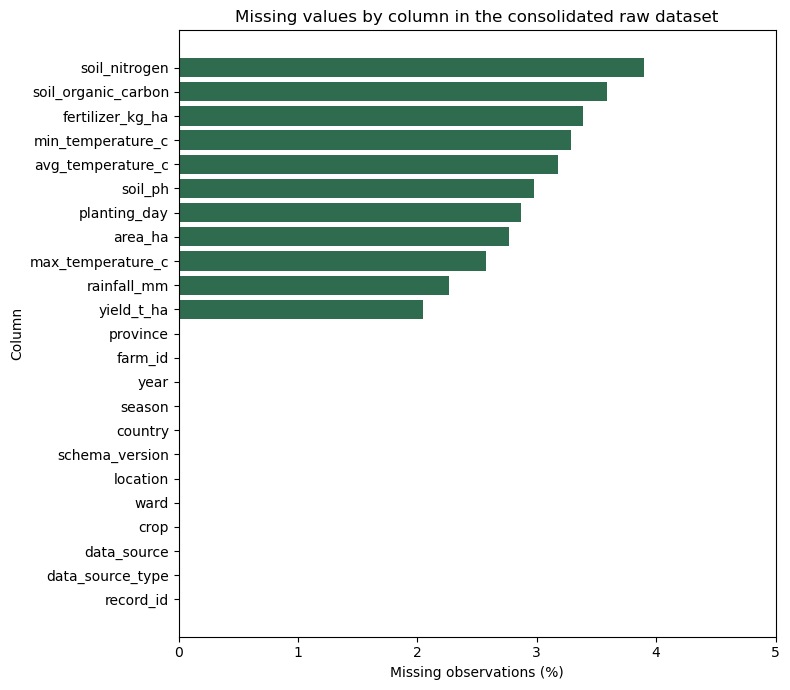

Missing values by column in the consolidated raw SmartCrop dataset. The file is synthetic. Blank cells were injected by the generator and are not survey non-response from Macheke.


In [9]:
figures_dir = DS_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plot_data = missing.sort_values("missing_percent", ascending=True)
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(plot_data["column"], plot_data["missing_percent"], color="#2F6B4F")
ax.set_title("Missing values by column in the consolidated raw dataset")
ax.set_xlabel("Missing observations (%)")
ax.set_ylabel("Column")
ax.set_xlim(0, max(5, float(plot_data["missing_percent"].max()) + 1))
fig.tight_layout()

figure_stem = figures_dir / "01_missing_values"
fig.savefig(figure_stem.with_suffix(".png"), dpi=150)
fig.savefig(figure_stem.with_suffix(".svg"))
fig.savefig(figure_stem.with_suffix(".pdf"))
plt.show()

caption = (
    "Missing values by column in the consolidated raw SmartCrop dataset. "
    "The file is synthetic. Blank cells were injected by the generator and "
    "are not survey non-response from Macheke."
)
figure_stem.with_suffix(".caption.txt").write_text(caption + "\n", encoding="utf-8")
print(caption)


## 8. Interpretation

Read the printed quality report above together with these points:

- A row count equal to the CSV rows plus the Excel rows means both batches were loaded and neither was filtered.
- `data_source_type` should be `SYNTHETIC` for every observation. If a future file introduces `REAL` or `EXTERNAL` measurements, those rows must keep their own label. They must not be silently stacked onto this synthetic file.
- Exact duplicate rows are expected at the generator's duplicate rate. They are copies, including the same `record_id`. Notebook 02 should decide how to drop them. This notebook only counts them.
- Missing values on rainfall, temperature, soil, fertilizer, planting day, area, or yield are expected. Missing values on `record_id`, `crop`, or `data_source_type` would mean the file was damaged.
- Values outside the plausible range are the generator's outliers, or ordinary tail values. Being outside the plausible range does not by itself say which treatment Notebook 02 should use.
- The source catalogue's `not_ingested` status means this pipeline does not yet contain NASA POWER, CHIRPS, SoilGrids, Agritex, or ZIMSTAT measurements. Do not describe the consolidated yield column as official Macheke statistics.

The yield values are an output of a documented formula plus noise. Association between rainfall and yield in this file is therefore partly built in. It is not evidence about Macheke farms.


In [10]:
synthetic_rows = int((consolidated["data_source_type"] == "SYNTHETIC").sum())
other_source_rows = int(len(consolidated) - synthetic_rows)
protected = ["record_id", "farm_id", "crop", "data_source_type", "location"]
protected_missing = int(consolidated[protected].isna().sum().sum())
maize_rows = int((consolidated["crop"] == "maize").sum())

print("Acquisition checks")
print("------------------")
print(f"Consolidated rows: {len(consolidated)}")
print(f"Columns: {consolidated.shape[1]}")
print(f"Synthetic rows: {synthetic_rows}")
print(f"Rows with another source type: {other_source_rows}")
print(f"Maize rows: {maize_rows}")
print(f"Missing values in identity columns {protected}: {protected_missing}")
print(f"Exact duplicate rows: {duplicates['exact_duplicate_rows']}")
print(f"Target column: yield_t_ha")
print(f"Non-missing yield rows: {int(consolidated['yield_t_ha'].notna().sum())}")
print(f"Saved consolidated file: {consolidated_path}")


Acquisition checks
------------------
Consolidated rows: 974
Columns: 23
Synthetic rows: 974
Rows with another source type: 0
Maize rows: 974
Missing values in identity columns ['record_id', 'farm_id', 'crop', 'data_source_type', 'location']: 0
Exact duplicate rows: 14
Target column: yield_t_ha
Non-missing yield rows: 954
Saved consolidated file: /home/marvelous/.dev/Tait/capstone/data-science/data/interim/consolidated_raw.csv


## 9. Conclusion

Notebook 01 loaded a CSV batch, an Excel batch, and an external source catalogue. The two observation batches were coerced to one schema and saved as `data/interim/consolidated_raw.csv`. The catalogue was inspected and left separate because it does not contain measurements.

The consolidated file is labelled synthetic maize data for Macheke, Mashonaland East. It is fit for the next development step, which is cleaning. It is not fit to be quoted as a description of real smallholder yields.

Assumptions that remain in force:

- Ward codes are placeholders.
- Season labels are not a historical weather series.
- Missing values, duplicates, and extreme values were injected so quality checks are observable.
- No real Macheke agricultural extract has been added in this phase.

**Next notebook:** data cleaning, using `consolidated_raw.csv` as the input. Cleaning is not done here.


---
# Part 2: Data Cleaning and Preparation

**Chapter 3 Stage:** Data Cleaning & Preparation  
**Original Source Notebook:** [`02_data_cleaning.ipynb`](02_data_cleaning.ipynb)  
**Execution Order:** Step 2 of 7  

Applies cleaning rules (deduplication, physical/plausible bounds blanking, dropping missing yield) and exports clean_dataset.csv.


# SmartCrop — Notebook 02: Data Cleaning

**Study area:** Macheke, Mashonaland East, Zimbabwe  
**Crop:** maize only  
**Target:** `yield_t_ha` (tonnes per hectare)  
**Input:** `data/interim/consolidated_raw.csv`  
**Output:** `data/processed/clean_dataset.csv`

> The input file is synthetic. Cleaning does not turn it into a Macheke survey.


## 1. Introduction

Notebook 01 consolidated two synthetic batches and left duplicates, blank cells, and a few impossible values in place. This notebook applies a written cleaning policy and saves the result. It does not impute feature gaps. Imputation is fitted later, on the training seasons only, so the clean file does not leak the test seasons.


## 2. Objectives

1. Count rows, missing cells, and exact duplicates before cleaning.
2. Remove exact duplicate rows.
3. Blank values outside physical bounds and outside the documented plausible bounds.
4. Blank average temperature where `min <= avg <= max` fails.
5. Drop rows with no yield. Those rows cannot supervise a model.
6. Export before/after tables as CSV, Excel, and HTML.


## 3. Dataset Description

The table is one synthetic farm in one synthetic season. `data_source_type` remains `SYNTHETIC`. Ward codes remain placeholders. Season labels remain labels, not a historical weather series. Yield is tonnes per hectare.


## 4. Methodology

Physical bounds mark values that cannot be a measurement of that quantity, such as a negative rainfall. Plausible bounds are project checks for the injected extremes, not official agronomic limits. A value outside either bound becomes missing. The rest of the row stays.

Temperature order is checked only when minimum, average, and maximum are all present. If the order fails, the average is blanked because that is the field the generator corrupted.

Exact duplicates are identical on every column, including `record_id`. The first copy is kept.

Rows with missing `yield_t_ha` are dropped after the blanking steps, so a yield that was an injected extreme is also dropped. Feature missingness is left for the model pipeline.


## 5. Implementation


In [11]:
from pathlib import Path
import sys
import pandas as pd

def find_root() -> Path:
    start = Path.cwd().resolve()
    candidates = [start, *start.parents]
    if (start / "data-science").is_dir():
        candidates.insert(0, start / "data-science")
    for candidate in candidates:
        if (candidate / "src" / "data" / "schema.py").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from the SmartCrop repository.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 120)

from data.cleaning import clean_observations, quality_tables, write_clean_outputs
from data.schema import coerce_observation_frame

raw = coerce_observation_frame(pd.read_csv(ROOT / "data" / "interim" / "consolidated_raw.csv"))
print(f"Rows before cleaning: {len(raw)}")
print(f"Exact duplicate rows before cleaning: {int(raw.duplicated().sum())}")
print(f"Missing yield rows before cleaning: {int(raw['yield_t_ha'].isna().sum())}")


Rows before cleaning: 974
Exact duplicate rows before cleaning: 14
Missing yield rows before cleaning: 20


In [12]:
clean, report = clean_observations(raw)
tables = quality_tables(raw, clean)
paths = write_clean_outputs(clean, report, tables, ROOT)
print(f"Rows after cleaning: {report['rows_after']}")
print(f"Exact duplicates removed: {report['exact_duplicates_removed']}")
print(f"Temperature rows repaired: {report['temperature_order_repairs']}")
print(f"Rows dropped for missing yield: {report['rows_dropped_for_missing_yield']}")
print(f"Missing cells before: {report['missing_cells_before']}")
print(f"Missing cells after: {report['missing_cells_after']}")
print(f"Imputation: {report['imputation']}")
display(tables["before_after"])
display(tables["missing_by_column"])


Rows after cleaning: 938
Exact duplicates removed: 14
Temperature rows repaired: 3
Rows dropped for missing yield: 22
Missing cells before: 320
Missing cells after: 308
Imputation: none in the clean file; the model pipeline imputes training medians


,stage,rows,columns,missing_cells,duplicate_rows
0,before,974,23,320,14
1,after,938,23,308,0


,column,missing_before,missing_after
0,record_id,0,0
1,farm_id,0,0
2,year,0,0
3,season,0,0
4,country,0,0
5,province,0,0
6,location,0,0
7,ward,0,0
8,crop,0,0
9,area_ha,27,25


## 6. Results

The tables above are the cleaning log. Duplicate rows should be zero after this step. Yield should have no missing values. Some feature cells remain missing on purpose.


## 7. Visualizations

Cleaning is summarised as a table rather than a chart. The missing-value figure for the cleaned file is drawn in Notebook 04, after this file exists.


## 8. Interpretation

Removing exact copies stops the same farm-season from counting twice. Blanking impossible and extreme values keeps the farm row but stops a single corrupted cell from dominating a split. Dropping missing yields is required for supervised learning. Leaving other gaps unfilled avoids choosing a median from seasons that will later be used as the test set.


## 9. Conclusion

`data/processed/clean_dataset.csv` is the modelling table. It is still synthetic maize data for the Macheke study area. The next notebook adds a short list of features that a prediction request can recompute.


---
# Part 3: Feature Engineering

**Chapter 3 Stage:** Feature Engineering  
**Original Source Notebook:** [`03_feature_engineering.ipynb`](03_feature_engineering.ipynb)  
**Execution Order:** Step 3 of 7  

Constructs the three engineered features (temperature_range_c, degrees_above_33_c, planting_delay_days) and writes the feature dictionary.


# SmartCrop — Notebook 03: Feature Engineering

**Target:** `yield_t_ha`  
**Principle:** add a feature only when it has an agronomic reading and the API can rebuild it from the raw inputs.


## 1. Introduction

The clean file already stores seasonal rainfall, seasonal temperatures, soil measures, fertilizer per hectare, and a planting-day index. Copying those columns under new names would not add information. This notebook adds three contrasts that the saved model can recompute at prediction time.


## 2. Objectives

1. Document every model input, including the columns that were deliberately not duplicated.
2. Add `temperature_range_c`, `degrees_above_33_c`, and `planting_delay_days`.
3. Export `reports/tables/feature_dictionary.xlsx`.


## 3. Dataset Description

The input is `clean_dataset.csv`. Source columns keep their units from the schema. Engineered columns are differences or clipped delays of those source columns. `area_ha` is not a yield feature. Production, when needed, is `yield_t_ha × area_ha` and is not used to predict yield.


## 4. Methodology

`temperature_range_c` is maximum minus minimum temperature. `degrees_above_33_c` is how far the maximum sits above 33°C, or zero when it does not. `planting_delay_days` is how many days the planting index falls after day 40, or zero when planting is earlier. Day 1 is 1 November, so day 40 is 10 December.

No critical-period rainfall feature is created. The file has one seasonal rainfall total, not dekadal rainfall. Inventing a critical-period column would pretend the file contains a split it does not have.


## 5. Implementation


In [13]:
from pathlib import Path
import sys
import pandas as pd

def find_root() -> Path:
    start = Path.cwd().resolve()
    candidates = [start, *start.parents]
    if (start / "data-science").is_dir():
        candidates.insert(0, start / "data-science")
    for candidate in candidates:
        if (candidate / "src" / "data" / "schema.py").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from the SmartCrop repository.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 120)

from data.schema import SYNTHETIC_DISCLAIMER
from features.engineering import (
    ENGINEERED_FEATURES,
    MODEL_FEATURES,
    RAW_FEATURES,
    add_engineered_features,
    feature_dictionary,
    write_feature_dictionary,
)

print(SYNTHETIC_DISCLAIMER)
clean = pd.read_csv(ROOT / "data" / "processed" / "clean_dataset.csv")
featured = add_engineered_features(clean)
dictionary_path = write_feature_dictionary(ROOT)
featured[MODEL_FEATURES + ["yield_t_ha"]].head()


SYNTHETIC DATA. These rows were generated by the SmartCrop synthetic generator for software and model-development exercises. They are not measurements from Macheke, Mashonaland East, Zimbabwe, and they must not be cited as agricultural statistics.


,rainfall_mm,avg_temperature_c,max_temperature_c,min_temperature_c,soil_ph,soil_nitrogen,soil_organic_carbon,fertilizer_kg_ha,planting_day,temperature_range_c,degrees_above_33_c,planting_delay_days,yield_t_ha
0,653.6,23.22,31.40,17.21,5.20,0.082,0.87,123.5,14.0,14.19,0.00,0.0,2.273
1,643.5,23.40,33.75,16.93,5.15,0.105,0.60,103.6,76.0,16.82,0.75,36.0,1.563
2,662.8,24.27,31.62,18.33,5.19,0.099,0.61,0.0,33.0,13.29,0.00,0.0,1.808
3,532.6,NaN,32.31,16.27,5.26,0.071,0.85,56.3,40.0,16.04,0.00,0.0,1.489
4,668.2,NaN,37.88,17.35,5.41,0.077,0.93,153.5,5.0,20.53,4.88,0.0,1.774


In [14]:
dictionary = feature_dictionary()
display(dictionary)
print("Raw inputs:", ", ".join(RAW_FEATURES))
print("Engineered:", ", ".join(ENGINEERED_FEATURES))
print(f"Feature dictionary: {dictionary_path}")
print(featured[ENGINEERED_FEATURES].describe().round(3))


,feature,kind,unit,definition
0,rainfall_mm,source,mm,Seasonal rainfall total already stored on the ...
1,avg_temperature_c,source,°C,Average temperature over the growing season. U...
2,max_temperature_c,source,°C,Mean daily maximum temperature over the growin...
3,min_temperature_c,source,°C,Mean daily minimum temperature over the growin...
4,soil_ph,source,pH,Topsoil pH.
5,soil_nitrogen,source,%,"Total soil nitrogen, percent by mass."
6,soil_organic_carbon,source,%,"Soil organic carbon, percent."
7,fertilizer_kg_ha,source,kg/ha,Fertilizer product already expressed per hecta...
8,planting_day,source,day index,Planting day index where 1 is 1 November.
9,temperature_range_c,engineered,°C,max_temperature_c minus min_temperature_c. Sum...


Raw inputs: rainfall_mm, avg_temperature_c, max_temperature_c, min_temperature_c, soil_ph, soil_nitrogen, soil_organic_carbon, fertilizer_kg_ha, planting_day
Engineered: temperature_range_c, degrees_above_33_c, planting_delay_days
Feature dictionary: /home/marvelous/.dev/Tait/capstone/data-science/reports/tables/feature_dictionary.xlsx
       temperature_range_c  degrees_above_33_c  planting_delay_days
count              883.000             913.000              910.000
mean                15.531               0.530                5.208
std                  1.993               1.183               11.159
min                 11.570               0.000                0.000
25%                 14.130               0.000                0.000
50%                 15.340               0.000                0.000
75%                 16.610               0.480                0.000
max                 23.830               6.790               60.000


## 6. Results

The dictionary has one row per model column. Engineered columns are present on the in-memory frame. They are not stored as a second copy of rainfall or fertilizer.


## 7. Visualizations

Feature distributions are part of Notebook 04, where they can be read next to yield.


## 8. Interpretation

A wider temperature range, heat above 33°C, and planting after 10 December are readable contrasts. Whether they help the model is an evaluation question, not something this notebook assumes. Soil and fertilizer stay in their original units.


## 9. Conclusion

The model matrix is the nine raw inputs plus three engineered columns. The prediction API will send the nine raw inputs. The saved pipeline rebuilds the three engineered columns, so a client cannot forget them or send a conflicting copy.


---
# Part 4: Exploratory and Descriptive Analysis

**Chapter 3 Stage:** Exploratory Data Analysis  
**Original Source Notebook:** [`04_eda_and_descriptive_analysis.ipynb`](04_eda_and_descriptive_analysis.ipynb)  
**Execution Order:** Step 4 of 7  

Calculates descriptive statistics, generates distributions and correlation matrices, and saves figures to reports/figures/.


# SmartCrop — Notebook 04: Exploratory and Descriptive Analysis

**Data status:** synthetic clean maize file. Associations below were partly built by the generator. They are not findings about Macheke farms.


## 1. Introduction

This notebook describes the clean file before any model is chosen. Charts use pairwise deletion. They do not fill missing values. Every figure is saved under `reports/figures/` with a title, axis labels, units, and a caption file.


## 2. Objectives

Describe yield, rainfall, temperature, season, ward, fertilizer, and soil. Show a correlation matrix. Rank the five strongest linear associations with yield. Export descriptive statistics.


## 3. Dataset Description

One row is a synthetic farm-season. Yield is tonnes per hectare. Seasons and wards are generator labels.


## 4. Methodology

Histograms and boxplots describe each variable. Scatter plots show pairwise association. Pearson correlation ranks linear association. The top five are the largest absolute correlations with `yield_t_ha`. Correlation is not causation, and it is not the permutation importance used later.


## 5. Implementation


In [15]:
from pathlib import Path
import sys
import pandas as pd

def find_root() -> Path:
    start = Path.cwd().resolve()
    candidates = [start, *start.parents]
    if (start / "data-science").is_dir():
        candidates.insert(0, start / "data-science")
    for candidate in candidates:
        if (candidate / "src" / "data" / "schema.py").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from the SmartCrop repository.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 120)

from data.schema import SYNTHETIC_DISCLAIMER
from visualization.eda import build_eda_figures

print(SYNTHETIC_DISCLAIMER)
clean = pd.read_csv(ROOT / "data" / "processed" / "clean_dataset.csv")
numeric = ["area_ha", "rainfall_mm", "avg_temperature_c", "max_temperature_c", "min_temperature_c", "soil_ph", "soil_nitrogen", "soil_organic_carbon", "fertilizer_kg_ha", "planting_day", "yield_t_ha"]
describe = clean[numeric].describe().round(3)
describe.to_csv(ROOT / "reports" / "tables" / "descriptive_statistics.csv")
describe.to_excel(ROOT / "reports" / "tables" / "descriptive_statistics.xlsx")
print(f"Rows: {len(clean)}. Seasons: {clean['season'].nunique()}. Wards: {clean['ward'].nunique()}.")
display(describe)


SYNTHETIC DATA. These rows were generated by the SmartCrop synthetic generator for software and model-development exercises. They are not measurements from Macheke, Mashonaland East, Zimbabwe, and they must not be cited as agricultural statistics.
Rows: 938. Seasons: 8. Wards: 6.


,area_ha,rainfall_mm,avg_temperature_c,max_temperature_c,min_temperature_c,soil_ph,soil_nitrogen,soil_organic_carbon,fertilizer_kg_ha,planting_day,yield_t_ha
count,913.000,908.000,904.000,913.000,908.000,910.000,901.000,903.000,902.00,910.000,938.000
mean,1.291,689.938,23.635,32.468,16.929,5.738,0.106,0.998,79.82,34.457,1.797
std,0.626,180.975,0.792,1.943,1.268,0.338,0.023,0.242,68.87,18.123,0.370
min,0.460,297.400,20.830,28.020,12.830,5.140,0.059,0.560,0.00,1.000,0.624
25%,0.830,539.400,23.108,31.200,16.030,5.480,0.087,0.785,30.00,22.000,1.563
50%,1.150,653.150,23.630,32.210,16.990,5.710,0.102,0.970,72.45,30.000,1.822
75%,1.470,856.700,24.202,33.480,17.812,6.010,0.127,1.200,115.90,40.000,2.059
max,4.450,1092.000,26.180,39.790,20.840,6.490,0.147,1.560,350.00,100.000,2.736


In [16]:
correlations = build_eda_figures(clean, ROOT / "reports" / "figures")
correlations.to_csv(ROOT / "reports" / "tables" / "feature_yield_correlations.csv", index=False)
print("Five strongest linear associations with yield")
display(correlations.head(5))


Five strongest linear associations with yield


,feature,correlation_with_yield
0,rainfall_mm,0.536246
1,fertilizer_kg_ha,0.379836
2,planting_delay_days,-0.276883
3,planting_day,-0.217463
4,avg_temperature_c,0.126634


## 6. Results

Descriptive statistics and the correlation ranking are printed above. Figure files include `yield_distribution`, `rainfall_vs_yield`, `temperature_vs_yield`, `correlation_matrix`, and `top_features`.


## 7. Visualizations

The saved figures carry the axis labels and captions. Open `reports/figures/` beside this notebook. A positive rainfall or fertilizer correlation is expected because the generator included those terms. A weak soil correlation means that, in this synthetic file, soil varies less than rainfall and fertilizer.


## 8. Interpretation

Use the printed top five as the descriptive answer to "which variables move together with yield in this file." Do not quote them as drivers of yield in Macheke. Season boxes compare generator season labels. Ward boxes compare placeholder codes.


## 9. Conclusion

The clean synthetic file is described and exported. Model choice is separate and uses a temporal split so later seasons are not used to pick the algorithm.


---
# Part 5: Model Training and Comparison

**Chapter 3 Stage:** Model Comparison  
**Original Source Notebook:** [`05_model_training.ipynb`](05_model_training.ipynb)  
**Execution Order:** Step 5 of 7  

Performs temporal cross-validation, trains candidate regressors on historical seasons, and exports model_comparison.csv.


# SmartCrop — Notebook 05: Model Training

**Target:** `yield_t_ha`  
**Candidates:** linear regression, decision tree, random forest, gradient boosting.  
XGBoost is not used. It is not required for this comparison.


## 1. Introduction

Training estimates maize yield per hectare from weather, soil, and management inputs. The saved object is a scikit-learn pipeline: feature builder, median imputer, and the regressor. The API loads that object. It does not fit a new model when a user asks for a prediction.


## 2. Objectives

1. Split seasons in time.
2. Fit four regressors on the earlier seasons.
3. Record training time, features, hyperparameters, validation metrics, and grouped cross-validation.
4. Save `reports/model_reports/model_comparison.csv`.


## 3. Dataset Description

The modelling frame is the clean synthetic file. Raw inputs are rainfall, three temperatures, soil pH, soil nitrogen, soil organic carbon, fertilizer, and planting day. The pipeline adds the three engineered columns from Notebook 03.


## 4. Methodology

Years are ordered. The earliest seasons train. The third-from-last season validates. The last two seasons are held out and are not used in this notebook.

The imputer learns medians on the training rows inside the pipeline. Grouped cross-validation splits the training window by season, so a whole season is held out of each fold. The test seasons never enter those folds.

Model choice, in the next notebooks, uses validation R². Lower validation RMSE breaks a tie.


## 5. Implementation


In [17]:
from pathlib import Path
import sys
import pandas as pd

def find_root() -> Path:
    start = Path.cwd().resolve()
    candidates = [start, *start.parents]
    if (start / "data-science").is_dir():
        candidates.insert(0, start / "data-science")
    for candidate in candidates:
        if (candidate / "src" / "data" / "schema.py").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from the SmartCrop repository.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 120)

from data.schema import SYNTHETIC_DISCLAIMER
from models.training import RANDOM_SEED, run_model_comparison


clean = pd.read_csv(ROOT / "data" / "processed" / "clean_dataset.csv")
comparison, details = run_model_comparison(clean, RANDOM_SEED)
out = ROOT / "reports" / "model_reports"
out.mkdir(parents=True, exist_ok=True)
comparison.to_csv(out / "model_comparison.csv", index=False)
comparison.to_excel(out / "model_comparison.xlsx", index=False)
print("Train years:", details["masks"]["train_years"])
print("Validation years:", details["masks"]["validation_years"])
print("Held-out test years (not scored here):", details["masks"]["test_years"])
display(comparison.drop(columns=["hyperparameters", "features"]))


Train years: [2017, 2018, 2019, 2020, 2021]
Validation years: [2022]
Held-out test years (not scored here): [2023, 2024]


,model_name,training_seconds,validation_mae,validation_rmse,validation_r2,cv_mae,cv_rmse,cv_r2,train_rows,validation_rows
0,Random Forest Regressor,0.3794,0.2850,0.3516,-0.3097,0.1576,0.1979,0.4812,585,118
1,Gradient Boosting Regressor,0.2049,0.2932,0.3581,-0.3585,0.1542,0.1945,0.4983,585,118
2,Decision Tree Regressor,0.0042,0.2984,0.3706,-0.4551,0.1910,0.2395,0.2377,585,118
3,Linear Regression,0.0163,0.3861,0.4505,-1.1501,0.1784,0.2284,0.3109,585,118


## 6. Results

The comparison table lists each algorithm, its validation MAE, RMSE, and R², and the mean grouped cross-validation scores on the training window. R² is the coefficient of determination. It is not accuracy.


## 7. Visualizations

Training comparison is a table. Residual and importance plots belong to the evaluation notebook, after a model has been selected.


## 8. Interpretation

A higher validation R² means the model explained more of the yield variation in the validation season. That season is still synthetic. A fast linear model can be preferred only when its validation score leads. Hyperparameters are fixed and documented in the saved table. They were not searched on the test seasons.


## 9. Conclusion

Four models have validation scores. Notebook 06 evaluates the selection rule and the held-out seasons. Notebook 07 writes the single serialized model.


---
# Part 6: Model Evaluation and Diagnostics

**Chapter 3 Stage:** Model Evaluation  
**Original Source Notebook:** [`06_model_evaluation.ipynb`](06_model_evaluation.ipynb)  
**Execution Order:** Step 6 of 7  

Selects the best algorithm on validation R², evaluates performance on held-out test seasons, tests the R² >= 0.80 target, and computes permutation importance.


# SmartCrop — Notebook 06: Model Evaluation

Metrics are MAE (t/ha), RMSE (t/ha), and R². This notebook does not report classification accuracy.


## 1. Introduction

Evaluation asks two questions. Which candidate should be kept, using only the validation season? Once that choice is fixed, what error does it make on later seasons that it has not seen?


## 2. Objectives

1. Select the model with the best validation R².
2. Score that model on the held-out seasons.
3. Compare the test R² with an 80% target defined as R² >= 0.80.
4. Plot actual against predicted, residuals, and the error distribution.
5. Rank inputs with permutation importance and list the top five.


## 3. Dataset Description

The same clean synthetic file and temporal split as Notebook 05. Importance is computed on the validation season so the test season is used for the error summary rather than for explanation.


## 4. Methodology

The academic 80% target, where a project statement asks for it, is defined here as test-set R² of at least 0.80. R² is the share of yield variance the predictions track. It is not the percentage of farms predicted exactly, and it is not classification accuracy.

Permutation importance shuffles one raw input at a time and records the drop in validation R². A large drop means the fitted model was using that input. It does not mean the input caused yield in Macheke.


## 5. Implementation


In [18]:
from pathlib import Path
import sys
import pandas as pd

def find_root() -> Path:
    start = Path.cwd().resolve()
    candidates = [start, *start.parents]
    if (start / "data-science").is_dir():
        candidates.insert(0, start / "data-science")
    for candidate in candidates:
        if (candidate / "src" / "data" / "schema.py").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from the SmartCrop repository.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 120)

from data.schema import SYNTHETIC_DISCLAIMER
from evaluation.metrics import regression_metrics
from models.training import (
    PERFORMANCE_TARGET_R2,
    RANDOM_SEED,
    evaluate_split,
    fit_final_model,
    permutation_feature_importance,
    run_model_comparison,
    select_model_name,
)
from reporting.model_report import prediction_frame, save_evaluation_figures

print(SYNTHETIC_DISCLAIMER)
clean = pd.read_csv(ROOT / "data" / "processed" / "clean_dataset.csv")
comparison, _details = run_model_comparison(clean, RANDOM_SEED)
chosen = select_model_name(comparison)
model, masks = fit_final_model(clean, chosen, RANDOM_SEED)
validation = clean.loc[clean["year"].isin(masks["validation_years"])]
test = clean.loc[clean["year"].isin(masks["test_years"])]
validation_metrics = evaluate_split(model, validation)
test_metrics = evaluate_split(model, test)
importance = permutation_feature_importance(model, validation, RANDOM_SEED)
evaluated = prediction_frame(model, test)
print(f"Selected on validation R²: {chosen}")
print(f"Validation MAE {validation_metrics['mae']:.3f}, RMSE {validation_metrics['rmse']:.3f}, R² {validation_metrics['r2']:.3f}")
print(f"Test MAE {test_metrics['mae']:.3f}, RMSE {test_metrics['rmse']:.3f}, R² {test_metrics['r2']:.3f}")
print(f"80% target means test R² >= {PERFORMANCE_TARGET_R2:.2f}. Met: {test_metrics['r2'] >= PERFORMANCE_TARGET_R2}")
display(importance)


ModuleNotFoundError: No module named 'reportlab'

In [19]:
reports = ROOT / "reports" / "model_reports"
reports.mkdir(parents=True, exist_ok=True)
metrics = pd.DataFrame([
    {"split": "validation", "mae": validation_metrics["mae"], "rmse": validation_metrics["rmse"], "r2": validation_metrics["r2"]},
    {"split": "test", "mae": test_metrics["mae"], "rmse": test_metrics["rmse"], "r2": test_metrics["r2"]},
])
metrics.to_csv(reports / "model_metrics.csv", index=False)
comparison.to_excel(reports / "model_comparison.xlsx", index=False)
importance.to_csv(reports / "feature_importance.csv", index=False)
evaluated.to_csv(reports / "sample_predictions.csv", index=False)
save_evaluation_figures(evaluated, importance, ROOT / "reports" / "figures")
print("Wrote actual_vs_predicted, residuals, prediction_error_distribution, and feature_importance figures.")
display(metrics.round(4))
display(evaluated.head())


NameError: name 'validation_metrics' is not defined

## 6. Results

Read the printed test MAE, RMSE, and R². The target line states whether test R² reached 0.80. The importance table is ranked. Near-zero or negative importance means shuffling that input did not reduce validation R².


## 7. Visualizations

`actual_vs_predicted.png` plots the test seasons against the equality line. `residuals.png` plots error against the prediction. `prediction_error_distribution.png` is the histogram of those errors, in tonnes per hectare. `feature_importance.png` shows the five highest permutation scores.


## 8. Interpretation

Judge the model by tonnes per hectare of error, not by an accuracy percentage. If R² is below 0.80, the model does not meet the stated target on these held-out synthetic seasons. Feature importance indicates variables that contributed strongly to model predictions. It does not prove causation, and the generator itself planted relationships for rainfall, fertilizer, and planting day.


## 9. Conclusion

The selected algorithm and its test metrics are fixed before serialization. Notebook 07 saves the pipeline and the metadata the API will load.


---
# Part 7: Final Model and Deployment Preparation

**Chapter 3 Stage:** Final Model & Deployment Preparation  
**Original Source Notebook:** [`07_final_model.ipynb`](07_final_model.ipynb)  
**Execution Order:** Step 7 of 7  

Fits the final pipeline on training seasons, serializes smartcrop_model.joblib and model_metadata.json, and exports final reports.


# SmartCrop — Notebook 07: Final Model

This notebook writes `models/trained/smartcrop_model.joblib` and `models/metadata/model_metadata.json`. The Django API loads those files and does not retrain them.


## 1. Introduction

One pipeline is saved: the algorithm chosen on validation R², fitted to the earlier seasons, with the feature builder and the median imputer inside the file. Sample predictions from the test seasons are exported with the report.


## 2. Objectives

1. Refit the selected model.
2. Record test metrics, row counts, features, seed, and library versions.
3. Save the joblib file, the metadata, sample predictions, and the HTML and PDF report.
4. Copy the artifact into `backend/ml_models/` for the API.


## 3. Dataset Description

Clean synthetic maize rows. Dataset version string: `synthetic-1.0.0`. Model version string: `1.0.0`.


## 4. Methodology

The selection rule is unchanged: highest validation R², then lower validation RMSE. Test metrics are stored after that choice. Metadata repeats the synthetic-data disclaimer so a later user of the file can see it without opening this notebook.


## 5. Implementation


In [20]:
from pathlib import Path
import sys
import pandas as pd

def find_root() -> Path:
    start = Path.cwd().resolve()
    candidates = [start, *start.parents]
    if (start / "data-science").is_dir():
        candidates.insert(0, start / "data-science")
    for candidate in candidates:
        if (candidate / "src" / "data" / "schema.py").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from the SmartCrop repository.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 120)

import json
import shutil
from data.schema import SYNTHETIC_DISCLAIMER
from models.training import (
    RANDOM_SEED,
    build_metadata,
    evaluate_split,
    fit_final_model,
    permutation_feature_importance,
    run_model_comparison,
    save_model,
    select_model_name,
)
from reporting.model_report import prediction_frame, save_evaluation_figures, write_final_report

print(SYNTHETIC_DISCLAIMER)
clean = pd.read_csv(ROOT / "data" / "processed" / "clean_dataset.csv")
comparison, _details = run_model_comparison(clean, RANDOM_SEED)
chosen = select_model_name(comparison)
model, masks = fit_final_model(clean, chosen, RANDOM_SEED)
train = clean.loc[clean["year"].isin(masks["train_years"])]
validation = clean.loc[clean["year"].isin(masks["validation_years"])]
test = clean.loc[clean["year"].isin(masks["test_years"])]
validation_metrics = evaluate_split(model, validation)
test_metrics = evaluate_split(model, test)
importance = permutation_feature_importance(model, validation, RANDOM_SEED)
samples = prediction_frame(model, test)
metadata = build_metadata(
    chosen,
    comparison,
    test_metrics,
    validation_metrics,
    train_rows=len(train),
    validation_rows=len(validation),
    test_rows=len(test),
    seed=RANDOM_SEED,
    feature_importance=importance.round(6).to_dict(orient="records"),
)
paths = save_model(model, metadata, ROOT)
save_evaluation_figures(samples, importance, ROOT / "reports" / "figures")
reports = write_final_report(ROOT, metadata, comparison, importance, samples)
backend = ROOT.parent / "backend" / "ml_models"
backend.mkdir(parents=True, exist_ok=True)
shutil.copy2(paths["model"], backend / "smartcrop_model.joblib")
shutil.copy2(paths["metadata"], backend / "model_metadata.json")
print(json.dumps({
    "algorithm": metadata["algorithm"],
    "version": metadata["version"],
    "test_r2": metadata["metrics"]["test_r2"],
    "target_met": metadata["performance_target"]["met"],
    "model": str(paths["model"]),
    "html": str(reports["html"]),
    "pdf": str(reports["pdf"]),
}, indent=2))
display(samples.head(8))


ModuleNotFoundError: No module named 'reportlab'

## 6. Results

The printed JSON is the serialization receipt: algorithm, version, test R², whether the 0.80 R² target was met, and the file paths. Sample test predictions are displayed. They are model output, not observations.


## 7. Visualizations

The report embeds the actual-versus-predicted figure. The HTML and PDF reports are written to `reports/final_model_report.html` and `reports/final_model_report.pdf`.


## 8. Interpretation

Use the saved metrics as the performance of this synthetic experiment. A prediction from the API is an estimate from this pipeline. It is not a guaranteed yield, and it is not a measurement from a Macheke field.


## 9. Conclusion

The research path from the consolidated file to a versioned model file is complete for maize in the Macheke study area. Later seasons were held out. The API should load `smartcrop_model.joblib` and refuse to train during a request.


---
# Appendix: Reproducibility, Ethics, and Agronomic Limitations

### Reproducibility Controls
- Random seed: `RANDOM_SEED = 42` is fixed across data generation, temporal splitting, cross-validation, and permutation importance.
- Preprocessing integrity: Median imputation is fit exclusively on the training season window inside the scikit-learn pipeline, preventing data leakage into validation/test splits.
- Feature alignment: The 9 raw features and 3 engineered features match the exact operational production schema.

### Agricultural and Methodological Disclaimers
1. **Synthetic Training Baseline:** The baseline dataset contains synthetic observations. It is not an empirical agronomic survey of Macheke smallholder farms.
2. **Non-Causal Feature Importance:** Permutation importance reflects statistical association inside the fitted model. It does not establish causal fertilizer responses.
3. **Study Area Approximation:** Boundary coordinates represent an experimental study area bounding box around Macheke, not an official administrative boundary.
4. **Production Model Advice:** Predictions must be accompanied by confidence limitations and should not be treated as guaranteed harvest yields.